# Module 4: Choosing pairs by clustering

The distance method pairs stocks whose *prices* stayed close. That misses stocks that move
together but have drifted apart, and it favours low-volatility names that simply never
separate. This module clusters stocks by their returns — the only machine learning on the
main path — and compares the pairs that come out with the distance-method pairs.

1. Simulate returns from hidden groups and recover the groups
2. PCA of U2 returns: the market, then the sectors
3. k-means and hierarchical clustering, compared with GICS sectors
4. Pairs the distance method misses
5. Both pair lists, same windows, same threshold rule
6. Exercises

Lecture notes: [`lecture.md`](lecture.md). New code: `statarb.selection`.

In [1]:
import logging
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram
from sklearn.metrics import adjusted_rand_score, silhouette_score

from statarb import data, returns, universe
from statarb.config import TRADING_DAYS
from statarb.pairs import distance
from statarb.selection import (
    candidate_pairs,
    hierarchical_clusters,
    kmeans_clusters,
    pca_features,
)
from statarb.signals import threshold_positions

logging.getLogger("yfinance").setLevel(logging.CRITICAL)
pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


def performance(daily: pd.Series) -> pd.Series:
    """Annualised mean, volatility and their ratio (a Sharpe ratio without the risk-free rate)."""
    mean, vol = daily.mean() * TRADING_DAYS, daily.std() * np.sqrt(TRADING_DAYS)
    return pd.Series({"ann. return": mean, "ann. volatility": vol, "Sharpe": mean / vol})


SECTOR = pd.Series({t: s for s, names in universe.LARGE_CAP_100_BY_SECTOR.items() for t in names})
_sector_names = list(SECTOR.unique())
SECTOR_COLOURS = dict(
    zip(_sector_names, list(plt.cm.tab20.colors[: len(_sector_names)]), strict=True)
)

## 1. Simulate first

Three groups, four stocks each. Every stock in a group is driven by that group's factor plus
a little idiosyncratic noise, so the returns are highly correlated inside a group and
uncorrelated across groups. The second half of each group also has a daily drift: the
returns still share the factor, but the prices walk away from the first half.

In [2]:
rng = np.random.default_rng(0)
n_days, n_groups, per_group = 400, 3, 4
factors = rng.normal(0.0, 0.012, size=(n_days, n_groups))
columns, groups = {}, {}
for g in range(n_groups):
    for i in range(per_group):
        name = f"g{g}s{i}"
        drift = 0.0015 if i >= per_group // 2 else 0.0
        columns[name] = drift + factors[:, g] + rng.normal(0.0, 0.003, n_days)
        groups[name] = g
sim_returns = pd.DataFrame(columns, index=pd.bdate_range("2010-01-01", periods=n_days))
sim_prices = 100 * (1 + sim_returns).cumprod()
sim_groups = pd.Series(groups, name="group")

features = pca_features(sim_returns, n_components=3)
km = kmeans_clusters(features.embeddings, k=3, seed=0)
hier = hierarchical_clusters(sim_returns, n_clusters=3)
print("variance in the first 3 PCs:", round(float(features.explained_variance_ratio.sum()), 3))
print("k-means adjusted Rand:     ", adjusted_rand_score(sim_groups.loc[km.index], km))
print(
    "hierarchical adjusted Rand:",
    adjusted_rand_score(sim_groups.loc[hier.labels.index], hier.labels),
)

# The no-drift pair and the drifted pair inside group 0.
sim_corr = sim_returns.corr()
sim_ssd = distance.ssd_matrix(distance.normalise(sim_prices))
print("corr  g0s0-g0s1 (no drift)", round(sim_corr.loc["g0s0", "g0s1"], 3))
print("corr  g0s0-g0s2 (drift)   ", round(sim_corr.loc["g0s0", "g0s2"], 3))
print(
    "SSD   g0s0-g0s1",
    round(sim_ssd.loc["g0s0", "g0s1"], 2),
    "  g0s0-g0s2",
    round(sim_ssd.loc["g0s0", "g0s2"], 2),
)
print("closest pair:", tuple(distance.select_pairs(sim_prices, n=1).iloc[0][["a", "b"]]))

variance in the first 3 PCs: 0.955
k-means adjusted Rand:      1.0
hierarchical adjusted Rand: 1.0
corr  g0s0-g0s1 (no drift) 0.937
corr  g0s0-g0s2 (drift)    0.941
SSD   g0s0-g0s1 2.04   g0s0-g0s2 23.17
closest pair: ('g2s0', 'g2s1')


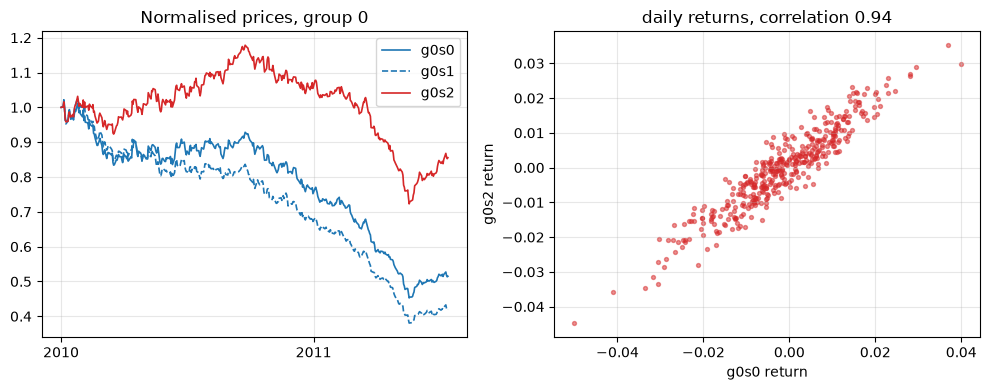

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
norm = distance.normalise(sim_prices)
for name, colour, style in (("g0s0", "C0", "-"), ("g0s1", "C0", "--"), ("g0s2", "C3", "-")):
    axes[0].plot(norm.index, norm[name], color=colour, ls=style, lw=1.2, label=name)
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_title("Normalised prices, group 0")
axes[0].legend()
axes[1].scatter(sim_returns["g0s0"], sim_returns["g0s2"], s=8, alpha=0.5, color="C3")
axes[1].set_xlabel("g0s0 return")
axes[1].set_ylabel("g0s2 return")
axes[1].set_title(f"daily returns, correlation {sim_corr.loc['g0s0', 'g0s2']:.2f}")
fig.tight_layout()
save(fig, "synthetic-groups.png")

**What it means:** g0s0 and g0s1 (both blue) stay on top of each other; g0s2 (red) shares the
factor but drifts away, so its price distance is several times larger. `select_pairs` returns
the close pair. Clustering on the returns puts all four stocks in one group, so
`candidate_pairs` keeps the drifted pair too. Both clusterings recover the three groups
exactly (adjusted Rand index 1).

## 2. Real returns: PCA

U2 is the 100 large caps, 2016–2025, adjusted closes. PCA is run on standardised returns:
each stock becomes a point whose coordinates are its loadings on the principal components.

In [4]:
prices = data.clean_prices(
    data.load_prices(universe.LARGE_CAP_100, start="2016-01-01", end="2025-12-31")
)
rets = returns.simple_returns(prices).iloc[1:]
print(prices.index[0].date(), "to", prices.index[-1].date(), prices.shape)

feat = pca_features(rets, n_components=15)
variance = feat.explained_variance_ratio
variance.head(6)

2016-01-04 to 2025-12-31 (2514, 100)


PC1    0.370
PC2    0.072
PC3    0.053
PC4    0.026
PC5    0.022
PC6    0.017
Name: explained_variance_ratio, dtype: float64

PC1 loadings, share positive: 1.0
                          PC2    PC3
Energy                 -0.133 -0.168
Financials             -0.086 -0.024
Industrials            -0.051 -0.037
Information Technology -0.034  0.137
Consumer Discretionary -0.015  0.072
Materials              -0.010  0.002
Communication Services  0.007  0.056
Health Care             0.075  0.019
Real Estate             0.093 -0.005
Consumer Staples        0.133 -0.021
Utilities               0.199 -0.088


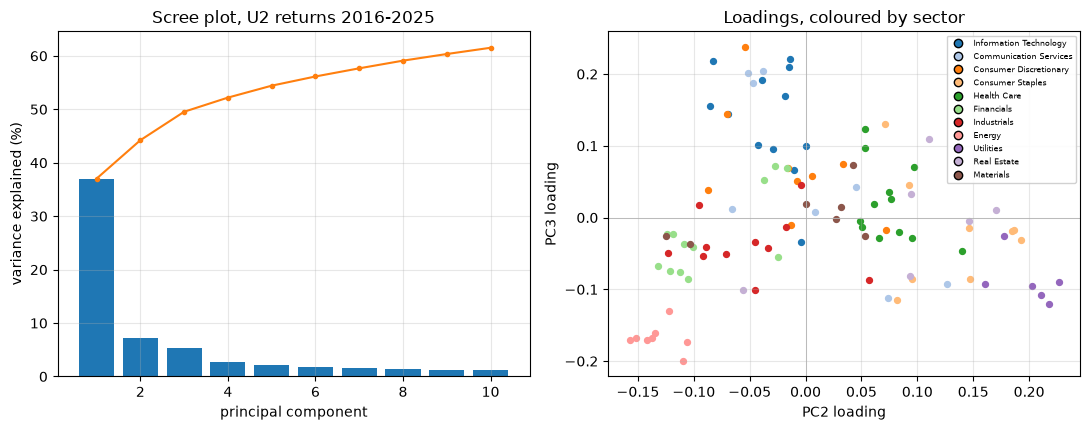

In [5]:
embeddings = feat.embeddings.copy()
if embeddings["PC1"].median() < 0:  # sign is arbitrary; face the market loadings upwards
    embeddings["PC1"] *= -1
loadings = embeddings[["PC2", "PC3"]].groupby(SECTOR).mean().sort_values("PC2")
print("PC1 loadings, share positive:", round(float((embeddings["PC1"] > 0).mean()), 2))
print(loadings.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].bar(range(1, 11), variance.iloc[:10] * 100, color="C0")
axes[0].plot(range(1, 11), variance.iloc[:10].cumsum() * 100, color="C1", marker="o", ms=3)
axes[0].set_xlabel("principal component")
axes[0].set_ylabel("variance explained (%)")
axes[0].set_title("Scree plot, U2 returns 2016-2025")
for ticker, row in embeddings.iterrows():
    axes[1].scatter(row["PC2"], row["PC3"], color=SECTOR_COLOURS[SECTOR[ticker]], s=18)
axes[1].axhline(0, color="0.7", lw=0.6)
axes[1].axvline(0, color="0.7", lw=0.6)
axes[1].set_xlabel("PC2 loading")
axes[1].set_ylabel("PC3 loading")
axes[1].set_title("Loadings, coloured by sector")
handles = [
    plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=c, label=s, ms=6)
    for s, c in SECTOR_COLOURS.items()
]
axes[1].legend(handles=handles, fontsize=6, loc="best", framealpha=0.9)
fig.tight_layout()
save(fig, "pca-scree-loadings.png")

**What it means:** the first component explains about 37% of the variance and every stock
loads on it positively: it is the market. The next components separate sectors. Utilities
and consumer staples sit at one end of PC2, energy and financials at the other; PC3 picks
out information technology against energy. The sign of a component is arbitrary.

## 3. Cluster, and compare with sectors

k-means runs on the loadings of PC2 to PC10, leaving out the market component (its loadings
barely differ across stocks, so it does not separate anyone). $k$ is chosen by the
**silhouette**: how much closer a stock is to its own cluster than to the next one, averaged
over stocks. Hierarchical clustering uses the correlation distance $1 - \mathrm{corr}$ and
average linkage, and the dendrogram shows the whole tree rather than one cut.

In [6]:
sector_space = embeddings.loc[:, "PC2":"PC10"]
silhouette = pd.Series(
    {
        k: silhouette_score(sector_space.to_numpy(), kmeans_clusters(sector_space, k, seed=0))
        for k in range(2, 16)
    },
    name="silhouette",
)
k_picture = 10  # on the plateau; the maximum is only marginally higher
labels = kmeans_clusters(sector_space, k_picture, seed=0)
hier = hierarchical_clusters(rets, n_clusters=11)


def purity(cluster_labels: pd.Series) -> float:
    frame = pd.DataFrame(
        {"c": cluster_labels.to_numpy(), "s": SECTOR.loc[cluster_labels.index].to_numpy()}
    )
    return sum(g["s"].value_counts().iloc[0] for _, g in frame.groupby("c")) / len(frame)


print(silhouette.round(3).to_string())
print(
    "k-means  ARI",
    round(adjusted_rand_score(SECTOR.loc[labels.index], labels), 2),
    " purity",
    round(purity(labels), 2),
)
print(
    "hier.    ARI",
    round(adjusted_rand_score(SECTOR.loc[hier.labels.index], hier.labels), 2),
    " purity",
    round(purity(hier.labels), 2),
)

counts = pd.crosstab(SECTOR.loc[labels.index], labels)
counts.columns = [f"c{c}" for c in counts.columns]
counts

2     0.174
3     0.159
4     0.195
5     0.216
6     0.261
7     0.321
8     0.345
9     0.369
10    0.381
11    0.370
12    0.384
13    0.388
14    0.376
15    0.377
k-means  ARI 0.54  purity 0.72
hier.    ARI 0.21  purity 0.48


,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9
row_0,,,,,,,,,,
Communication Services,0,1,0,0,3,0,4,0,0,0
Consumer Discretionary,0,4,3,0,2,0,0,0,0,0
Consumer Staples,0,0,0,0,0,0,0,0,9,0
Energy,0,0,0,8,0,0,0,0,0,0
Financials,9,3,0,0,0,0,0,0,0,0
Health Care,0,0,1,0,0,0,0,11,0,0
Industrials,0,5,1,0,0,0,0,0,0,5
Information Technology,0,2,0,0,10,0,0,0,0,0
Materials,0,1,1,0,0,0,0,0,0,5


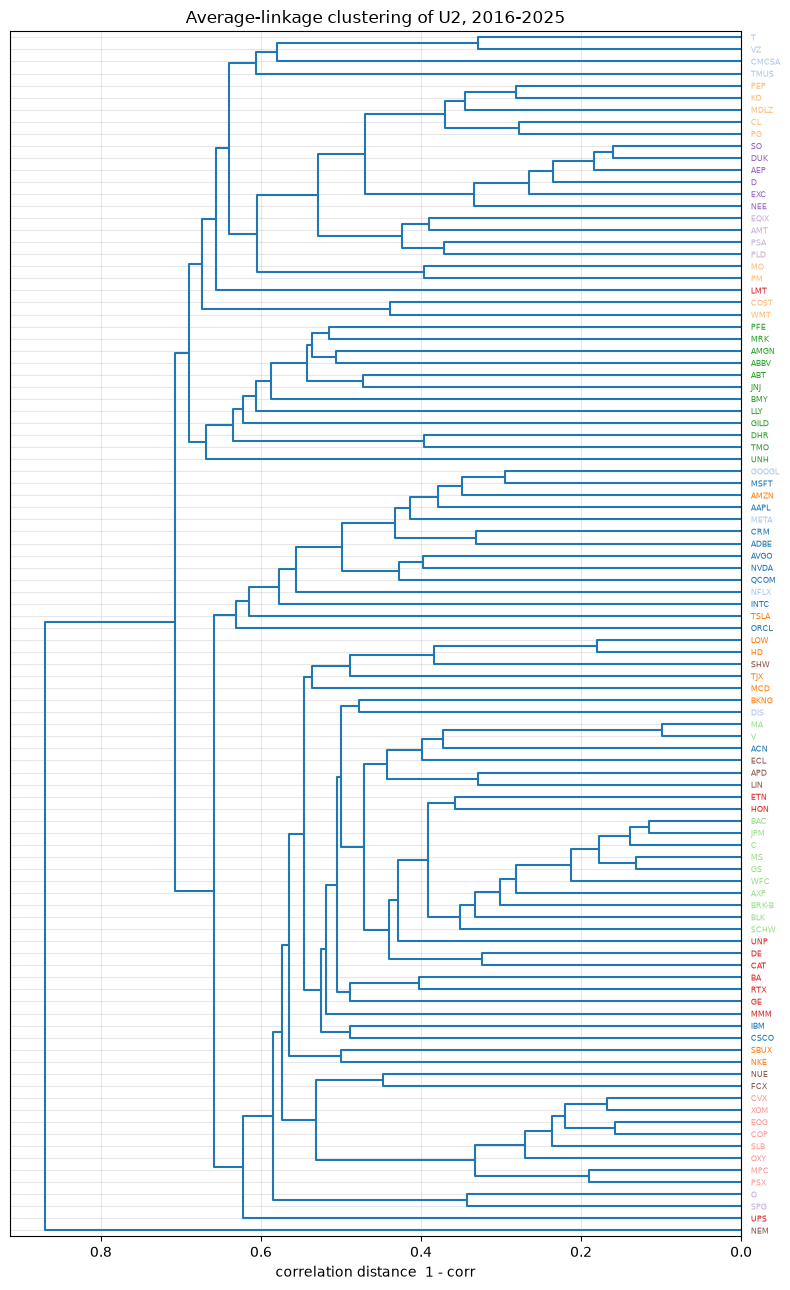

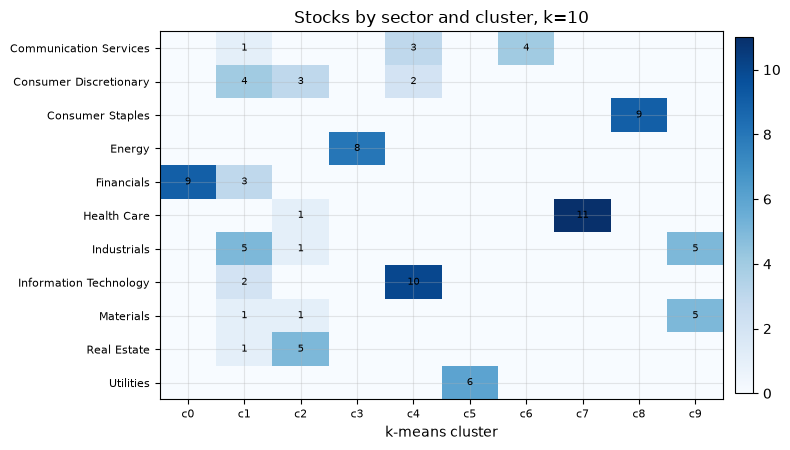

In [7]:
order = dendrogram(hier.linkage, labels=list(hier.labels.index), no_plot=True)["ivl"]
fig, ax = plt.subplots(figsize=(8, 13))
dendrogram(
    hier.linkage, labels=list(hier.labels.index), orientation="left", ax=ax, color_threshold=0
)
ax.tick_params(axis="y", labelsize=6)
ax.set_xlabel("correlation distance  1 - corr")
ax.set_title("Average-linkage clustering of U2, 2016-2025")
for tick in ax.get_yticklabels():
    tick.set_color(SECTOR_COLOURS[SECTOR[tick.get_text()]])
fig.tight_layout()
save(fig, "dendrogram.png")

fig, ax = plt.subplots(figsize=(8, 4.6))
im = ax.imshow(counts.to_numpy(), aspect="auto", cmap="Blues")
ax.set_xticks(range(counts.shape[1]), counts.columns, fontsize=8)
ax.set_yticks(range(counts.shape[0]), counts.index, fontsize=8)
for i in range(counts.shape[0]):
    for j in range(counts.shape[1]):
        value = int(counts.iloc[i, j])
        if value:
            ax.text(j, i, str(value), ha="center", va="center", fontsize=7)
ax.set_xlabel("k-means cluster")
ax.set_title(f"Stocks by sector and cluster, k={k_picture}")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
fig.tight_layout()
save(fig, "clusters-vs-sectors.png")

**What it means:** the silhouette climbs to about 0.35 by $k = 8$ and then only to about
0.39 at its maximum, so the cut is soft; $k = 10$ sits on that plateau. At that cut, 72% of
stocks sit in a cluster whose majority sector is their own (adjusted Rand 0.54 against GICS).
Energy, utilities, health care and staples each fall in one cluster; the banks do too.
The dendrogram, built from raw correlations rather than from the sector components, shows
the same blocks at the leaves (label colour is the sector). A single flat cut of that tree
into 11 clusters agrees with GICS less well, because the market factor makes every
correlation positive and some sectors are split across branches.

## 4. What the distance method misses

Over the whole decade the closest normalised prices are low-volatility defensives. Some are
genuine pairs (the utilities). Others just never moved much, so they stayed close without
sharing a business. Meanwhile two banks can be strongly correlated and still finish the
decade far apart, because one grew faster.

In [8]:
corr = rets.corr()
ssd = distance.ssd_matrix(distance.normalise(prices))
records = [
    (a, b, float(ssd.loc[a, b]), float(corr.loc[a, b]))
    for i, a in enumerate(ssd.columns)
    for b in list(ssd.columns)[i + 1 :]
]
ranked = (
    pd.DataFrame(records, columns=["a", "b", "ssd", "corr"])
    .sort_values("ssd")
    .reset_index(drop=True)
)
ranked.insert(0, "ssd_rank", ranked.index + 1)
show = ["DUK", "AEP", "VZ", "D", "WFC", "MS", "JPM", "C"]
keep = ranked[ranked["a"].isin(show) & ranked["b"].isin(show)]
keep

,ssd_rank,a,b,ssd,corr
0,1,DUK,AEP,47.046,0.825
1,2,VZ,D,73.634,0.439
121,122,WFC,C,271.170,0.795
153,154,VZ,C,301.945,0.267
303,304,C,D,425.182,0.261
...,...,...,...,...,...
3392,3393,MS,C,8457.580,0.817
3463,3464,JPM,D,9042.298,0.294
3589,3590,VZ,MS,10141.132,0.261
3607,3608,WFC,MS,10411.366,0.755


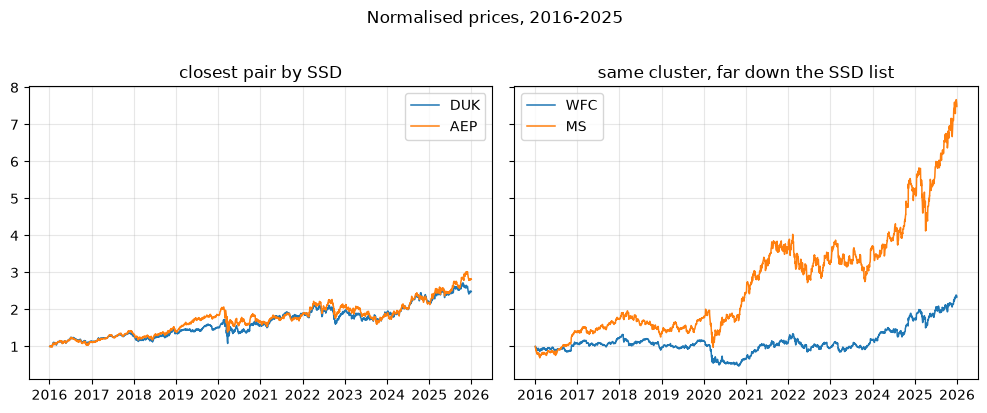

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
grown = distance.normalise(prices)
for ax, pair, title in (
    (axes[0], ("DUK", "AEP"), "closest pair by SSD"),
    (axes[1], ("WFC", "MS"), "same cluster, far down the SSD list"),
):
    for ticker in pair:
        ax.plot(grown.index, grown[ticker], lw=1.1, label=ticker)
    ax.set_title(title)
    ax.legend()
fig.suptitle("Normalised prices, 2016-2025", y=1.02)
fig.tight_layout()
save(fig, "missed-pair.png")

**What it means:** DUK and AEP are the closest pair of the 4,950 (correlation about 0.83).
VZ and D are second, with a correlation of only about 0.44: close in price, not a pair.
WFC and MS have correlation about 0.76 and k-means puts them in the same cluster, but MS
finished the decade at about 7.5 times its starting price and WFC at about 2.3, so they
rank around 3,600th by SSD. The distance method never looks at them. Clustering does.

## 5. Same universe, same windows, same rule

Every six months from 2017 to mid-2025: on the previous 252 days, take the closest pairs by
SSD and, separately, the most correlated pair inside each k-means cluster. $k$ is that
window's own silhouette maximum, over $k = 4$ to $12$. Both lists are the same length. Trade
the next 126 days with the Module 3 rule (enter at $\pm 2$ formation standard deviations,
exit at the crossing, one-day lag), and average across the pairs. No costs.

In [10]:
def window_book(form_px: pd.DataFrame, trade_px: pd.DataFrame, pairs: pd.DataFrame) -> pd.Series:
    columns = []
    for a, b in zip(pairs["a"], pairs["b"], strict=True):
        sigma = float(distance.spread(form_px, a, b).std(ddof=1))
        z = distance.spread(trade_px, a, b) / sigma
        position = threshold_positions(z, entry=2.0, exit=0.0)
        leg = returns.simple_returns(trade_px[[a, b]])
        columns.append(distance.pair_returns(position, leg[a], leg[b], lag=1))
    return pd.concat(columns, axis=1).mean(axis=1)


books, same_sector, overlap, chosen_k = [], [], [], []
snapshot = None
start = 252
while start + 126 <= len(prices.index):
    form_px = prices.iloc[start - 252 : start]
    trade_px = prices.iloc[start : start + 126]
    form_ret = returns.simple_returns(form_px).iloc[1:]
    space = pca_features(form_ret, n_components=10).embeddings.loc[:, "PC2":"PC10"]
    scores = {
        k: silhouette_score(space.to_numpy(), kmeans_clusters(space, k, seed=0))
        for k in range(4, 13)
    }
    k = max(scores, key=scores.get)
    cluster_labels = kmeans_clusters(space, k, seed=0)
    clustered = candidate_pairs(cluster_labels, form_ret, n_per_cluster=1, min_obs=100)
    closest = distance.select_pairs(form_px, n=len(clustered))
    books.append(
        pd.DataFrame(
            {
                "SSD pairs": window_book(form_px, trade_px, closest),
                "clustered pairs": window_book(form_px, trade_px, clustered),
            }
        )
    )
    same_sector.append(
        {
            "SSD pairs": np.mean(
                [SECTOR[a] == SECTOR[b] for a, b in zip(closest["a"], closest["b"], strict=True)]
            ),
            "clustered pairs": np.mean(
                [
                    SECTOR[a] == SECTOR[b]
                    for a, b in zip(clustered["a"], clustered["b"], strict=True)
                ]
            ),
        }
    )
    overlap.append(
        len(
            set(zip(closest["a"], closest["b"], strict=True))
            & set(zip(clustered["a"], clustered["b"], strict=True))
        )
        / len(clustered)
    )
    chosen_k.append(k)
    if form_px.index[0] >= pd.Timestamp("2022-01-01") and snapshot is None:
        snapshot = (form_px.index[0].date(), trade_px.index[0].date(), closest, clustered, k)
    start += 126

daily = pd.concat(books)
result = pd.DataFrame({name: performance(daily[name]) for name in daily.columns}).T
result["same sector"] = pd.DataFrame(same_sector).mean()
print(
    "windows:",
    len(books),
    " k median:",
    int(np.median(chosen_k)),
    " overlap:",
    round(float(np.mean(overlap)), 2),
)
print("from", daily.index[0].date(), "to", daily.index[-1].date())
result

windows: 17  k median: 11  overlap: 0.09
from 2017-01-03 to 2025-07-11


,ann. return,ann. volatility,Sharpe,same sector
SSD pairs,0.031,0.068,0.452,0.461
clustered pairs,0.025,0.039,0.645,0.956


In [11]:
form_start, trade_start, closest, clustered, k_snap = snapshot
print("formation starting", form_start, " trading starting", trade_start, " k =", k_snap)
ssd_view = closest.assign(sector_a=closest["a"].map(SECTOR), sector_b=closest["b"].map(SECTOR))
cluster_view = clustered.assign(
    sector_a=clustered["a"].map(SECTOR), sector_b=clustered["b"].map(SECTOR)
)
print("SSD pairs")
print(ssd_view.to_string(index=False))
print("clustered pairs")
print(cluster_view.to_string(index=False))

formation starting 2022-01-04  trading starting 2023-01-05  k = 11
SSD pairs
   a    b   ssd               sector_a               sector_b
  MA    V 0.232             Financials             Financials
 DHR  TMO 0.243            Health Care            Health Care
  MA   PG 0.284             Financials       Consumer Staples
 JNJ   KO 0.341            Health Care       Consumer Staples
 BLK   HD 0.348             Financials Consumer Discretionary
 ABT MSFT 0.368            Health Care Information Technology
AVGO EQIX 0.394 Information Technology            Real Estate
  CL    O 0.397       Consumer Staples            Real Estate
 ETN ORCL 0.403            Industrials Information Technology
 AEP   SO 0.441              Utilities              Utilities
  KO   PM 0.447       Consumer Staples       Consumer Staples
clustered pairs
    a    b  cluster  correlation               sector_a               sector_b
   MA    V        3        0.926             Financials             Financials
  COP

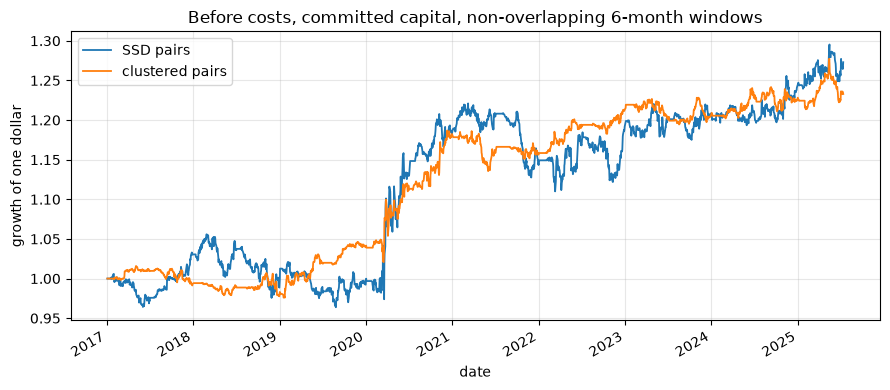

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
growth = (1 + daily).cumprod()
growth.plot(ax=ax, lw=1.3)
ax.set_ylabel("growth of one dollar")
ax.set_title("Before costs, committed capital, non-overlapping 6-month windows")
ax.legend()
fig.tight_layout()
save(fig, "clustered-vs-ssd.png")

**What it means:** the two lists barely overlap (about 9%), and they are not the same kind
of pair. In the 2022 formation year the distance list is led by MA/V but then fills up with
cross-sector names (MA/PG, JNJ/KO, ABT/MSFT); the cluster list is MA/V, COP/EOG, HD/LOW,
KO/PEP, the utilities, the defence names. Across all 17 windows, 96% of clustered pairs are
in the same sector against 46% of SSD pairs.

Traded with the same rule, neither book makes much before costs: about 3%/yr for the SSD
pairs (Sharpe 0.45) and about 2.5%/yr for the clustered pairs (Sharpe 0.64), with a standard
error near 0.4 on either Sharpe. Clustering finds pairs the distance method ignores. On this
universe it does not produce a reliably better backtest, and nothing here includes costs.

## 6. Exercises

1. **Include the market component.** Rerun k-means on PC1 to PC10 instead of PC2 to PC10
   and compare the adjusted Rand index. Why might it barely change?
2. **One pair the distance method ranks last.** Take the clustered pair with the worst SSD
   rank in a formation window and plot its spread over the following trading window. Does
   the threshold rule have anything to trade?
3. **A coarser tree.** Cut the dendrogram at a smaller number of clusters and rebuild the
   candidate pairs. What happens to the same-sector rate, and why?

In [13]:
# Exercise 1

In [14]:
# Exercise 2

In [15]:
# Exercise 3